In [80]:
import pandas as pd

df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")

In [81]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [82]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [83]:
df.isna().sum(axis=0)

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [84]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer, make_column_selector
import numpy as np


float_cols = ["annual_income", "lead_score"]
int_cols = ["number_of_courses_viewed", "interaction_count"]
cat_cols = ["lead_source", "industry", "employment_status", "location"]

float_pipeline = Pipeline([
  ("impute", SimpleImputer(strategy="constant", fill_value=0.0))
])

int_pipeline = Pipeline([
  ("impute", SimpleImputer(strategy="constant", fill_value=0))
])

cat_pipeline = Pipeline([
  ("impute", SimpleImputer(strategy="constant", fill_value="NA"))
])

preprocessing = ColumnTransformer([
  ("float", float_pipeline, float_cols),
  ("int", int_pipeline, int_cols),
  ("cat", cat_pipeline, cat_cols)
]).set_output(transform="pandas")

In [85]:
y = df["converted"].copy()
X_raw = df.drop(columns=["converted"])

X_processed = preprocessing.fit_transform(X_raw)

X_processed.head()


,float__annual_income,float__lead_score,int__number_of_courses_viewed,int__interaction_count,cat__lead_source,cat__industry,cat__employment_status,cat__location
0,88160.0,0.64,3,4,organic_search,technology,employed,europe
1,72688.0,0.72,3,7,social_media,technology,employed,south_america
2,44697.0,0.58,3,4,referral,retail,employed,europe
3,0.0,0.57,3,6,paid_ads,manufacturing,student,NA
4,24062.0,0.62,4,5,referral,manufacturing,student,north_america


In [86]:
X_processed.isna().sum(axis=0)

float__annual_income             0
float__lead_score                0
int__number_of_courses_viewed    0
int__interaction_count           0
cat__lead_source                 0
cat__industry                    0
cat__employment_status           0
cat__location                    0
dtype: int64

In [87]:
X_processed.dtypes

float__annual_income             float64
float__lead_score                float64
int__number_of_courses_viewed      int64
int__interaction_count             int64
cat__lead_source                     str
cat__industry                        str
cat__employment_status               str
cat__location                        str
dtype: object

In [88]:
X_processed["cat__industry"].mode()

0    technology
Name: cat__industry, dtype: str

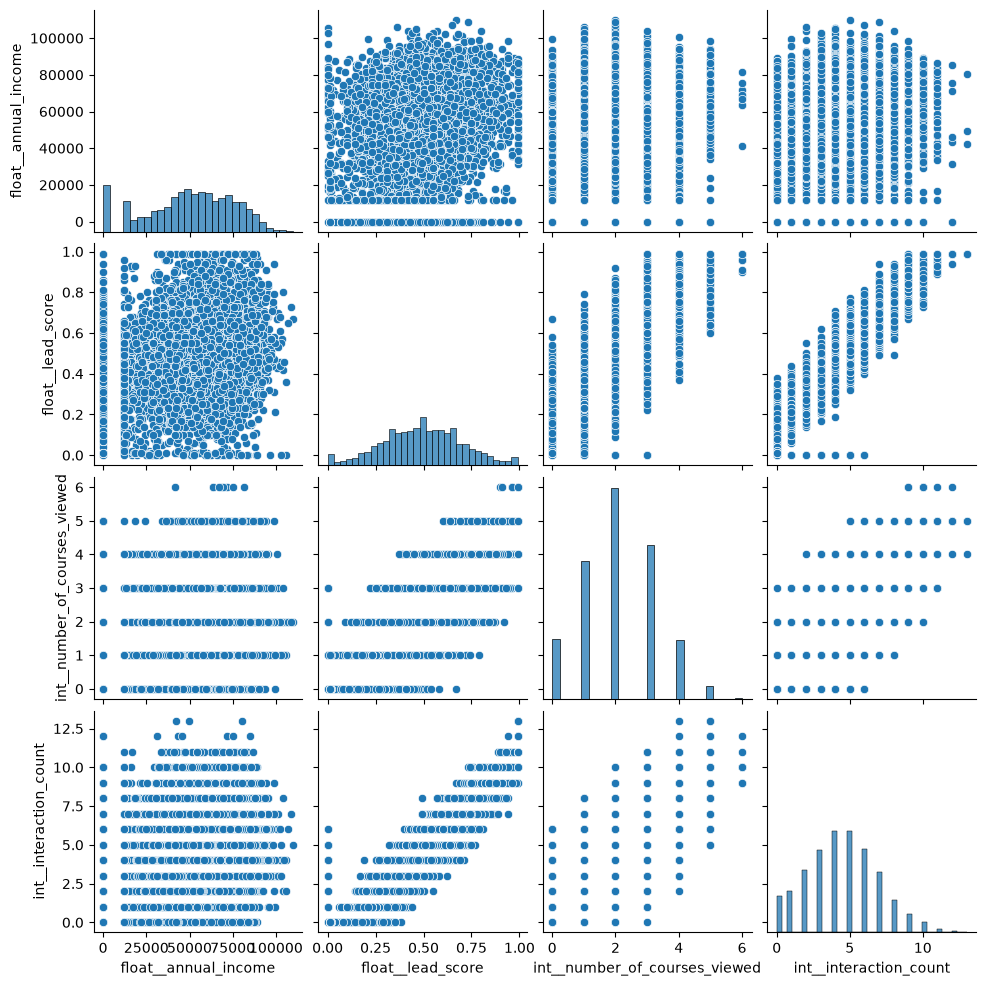

In [89]:
import seaborn as sns

sns.pairplot(X_processed)

In [90]:
cat_cols

['lead_source', 'industry', 'employment_status', 'location']

In [94]:
processed_num_df = X_processed.drop(["cat__"+c for c in cat_cols], axis=1).copy()
processed_num_df = pd.concat([processed_num_df, y], axis=1)
processed_num_df.head()

,float__annual_income,float__lead_score,int__number_of_courses_viewed,int__interaction_count,converted
0,88160.0,0.64,3,4,1
1,72688.0,0.72,3,7,1
2,44697.0,0.58,3,4,1
3,0.0,0.57,3,6,0
4,24062.0,0.62,4,5,1


In [95]:
processed_num_df.corr()

,float__annual_income,float__lead_score,int__number_of_courses_viewed,int__interaction_count,converted
float__annual_income,1.000000,0.229496,0.161300,0.122842,0.189652
float__lead_score,0.229496,1.000000,0.757204,0.915746,0.483246
int__number_of_courses_viewed,0.161300,0.757204,1.000000,0.721609,0.395038
int__interaction_count,0.122842,0.915746,0.721609,1.000000,0.448624
converted,0.189652,0.483246,0.395038,0.448624,1.000000


<Axes: >

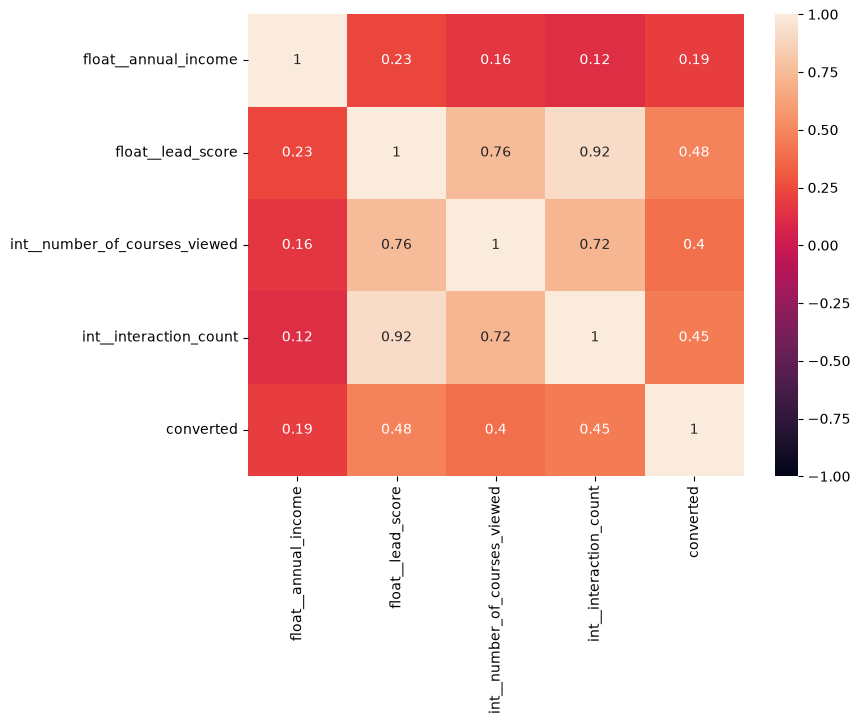

In [96]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.heatmap(processed_num_df.corr(), annot=True, vmin=-1.0, vmax=1.0)

In [99]:
from sklearn.model_selection import train_test_split
X_full = pd.concat([X_processed, y], axis=1)
df_full_train, df_test = train_test_split(X_full, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

In [100]:
df_train.head()

,float__annual_income,float__lead_score,int__number_of_courses_viewed,int__interaction_count,cat__lead_source,cat__industry,cat__employment_status,cat__location,converted
4702,65980.0,0.37,2,3,paid_ads,finance,employed,asia,1
2155,71662.0,0.09,0,0,events,finance,employed,south_america,0
289,40220.0,0.55,2,5,referral,NA,employed,asia,1
1822,88352.0,0.45,2,2,organic_search,finance,employed,north_america,0
3442,89316.0,0.00,1,5,events,technology,employed,north_america,1


In [105]:
from sklearn.feature_selection import mutual_info_classif

X_mi = df_train.drop(["converted"], axis=1).copy()
y_mi = df_train["converted"]

for colname in X_mi.select_dtypes("object"):
  X_mi[colname], _ = X_mi[colname].factorize()

discrete_features = X_mi.dtypes == int

def make_mi_score(X, y, discrete_features):
  score = mutual_info_classif(X, y, discrete_features=discrete_features)
  score = pd.Series(score, name="MI Scores", index=X_mi.columns)
  score = score.sort_values(ascending=False)
  return round(score, 2)

make_mi_score(X_mi, y_mi, discrete_features)

/tmp/ipykernel_3355/2082409258.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for colname in X_mi.select_dtypes("object"):


float__lead_score                0.14
int__interaction_count           0.12
int__number_of_courses_viewed    0.08
cat__lead_source                 0.03
cat__employment_status           0.02
float__annual_income             0.01
cat__industry                    0.00
cat__location                    0.00
Name: MI Scores, dtype: float64

In [126]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")

In [127]:
from sklearn.preprocessing import OneHotEncoder

cat_pipeline = Pipeline([
  ("impute", SimpleImputer(strategy="constant", fill_value="NA")),
  ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessing = ColumnTransformer([
  ("float", float_pipeline, float_cols),
  ("int", int_pipeline, int_cols),
  ("cat", cat_pipeline, cat_cols)
]).set_output(transform="pandas")

In [128]:
y = df["converted"].copy()
X_raw = df.drop(columns=["converted"])

X_processed = preprocessing.fit_transform(X_raw)
X_full_train, X_test, y_full, y_test = train_test_split(X_processed, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
    X_full_train, y_full, test_size=0.25, random_state=42
)

X_train.head()

,float__annual_income,float__lead_score,int__number_of_courses_viewed,int__interaction_count,cat__lead_source_NA,cat__lead_source_events,cat__lead_source_organic_search,cat__lead_source_paid_ads,cat__lead_source_referral,cat__lead_source_social_media,...,cat__employment_status_employed,cat__employment_status_self_employed,cat__employment_status_student,cat__employment_status_unemployed,cat__location_NA,cat__location_africa,cat__location_asia,cat__location_europe,cat__location_north_america,cat__location_south_america
4702,65980.0,0.37,2,3,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2155,71662.0,0.09,0,0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
289,40220.0,0.55,2,5,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1822,88352.0,0.45,2,2,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3442,89316.0,0.00,1,5,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [130]:
X_train.dtypes

float__annual_income                    float64
float__lead_score                       float64
int__number_of_courses_viewed             int64
int__interaction_count                    int64
cat__lead_source_NA                     float64
cat__lead_source_events                 float64
cat__lead_source_organic_search         float64
cat__lead_source_paid_ads               float64
cat__lead_source_referral               float64
cat__lead_source_social_media           float64
cat__industry_NA                        float64
cat__industry_education                 float64
cat__industry_finance                   float64
cat__industry_healthcare                float64
cat__industry_manufacturing             float64
cat__industry_retail                    float64
cat__industry_technology                float64
cat__employment_status_NA               float64
cat__employment_status_employed         float64
cat__employment_status_self_employed    float64
cat__employment_status_student          

In [131]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_val)
acc = accuracy_score(y_val, y_pred)
print(round(acc, 2))

0.65


In [151]:
def get_accuracy(X, y, X_test, y_test):
  
  model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000, random_state=42)
  model.fit(X, y)
  y_pred = model.predict(X_test)
  return accuracy_score(y_test, y_pred)

def get_feature_score(X, y, drop_feature=None) -> float:
  if drop_feature:
    X_new = X.drop(columns=[drop_feature])
    cur_float_cols = [c for c in float_cols if c != drop_feature]
    cur_int_cols = [c for c in int_cols if c != drop_feature]
    cur_cat_cols = [c for c in cat_cols if c != drop_feature]
    local_preprocessing = ColumnTransformer([
      ("float", float_pipeline, cur_float_cols),
      ("int", int_pipeline, cur_int_cols),
      ("cat", cat_pipeline, cur_cat_cols)
    ]).set_output(transform="pandas")
    X_processed = local_preprocessing.fit_transform(X_new)
  else:
    X_processed = preprocessing.fit_transform(X)
  X_train, X_val, y_train, y_val = train_test_split(
      X_processed, y, test_size=0.25, random_state=42
  )
  acc_score = get_accuracy(X_train, y_train, X_val, y_val)
  return float(acc_score)



In [152]:
y = df["converted"].copy()
X_raw = df.drop(columns=["converted"])
X_full, X_test, y_full, y_test = train_test_split(X_raw, y, test_size=0.2, random_state=42)

X_full.columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score'],
      dtype='str')

In [157]:
from operator import itemgetter

normal_acc = get_feature_score(X_full.copy(), y_full.copy())

result = {}
for col in X_full.columns:
  X = X_full.copy()
  y = y_full.copy()
  acc_score = get_feature_score(X, y, col)
  result[col] = normal_acc - acc_score

sorted_result = dict(sorted(result.items(), key=itemgetter(1)))
print(sorted_result)

{'annual_income': -0.07899999999999996, 'industry': 0.0, 'employment_status': 0.0, 'location': 0.0, 'lead_score': 0.0010000000000000009, 'number_of_courses_viewed': 0.0020000000000000018, 'lead_source': 0.0030000000000000027, 'interaction_count': 0.04400000000000004}


In [159]:
y = df["converted"].copy()
X_raw = df.drop(columns=["converted"])
X_processed = preprocessing.fit_transform(X_raw)
X_full_train, X_test, y_full, y_test = train_test_split(X_processed, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
    X_full_train, y_full, test_size=0.25, random_state=42
)

C = [0.000001, 0.00001, 0.0001, 0.001]

acc_result1 = {}
acc_result2 = {}

for c in C:
  X_tr = X_train.copy()
  y_tr = y_train.copy()
  X_vl = X_val.copy()
  y_vl = y_val.copy()
  model1 = LogisticRegression(solver="liblinear", C=c, max_iter=1000, random_state=42, l1_ratio=0) 
  model2 = LogisticRegression(solver="liblinear", C=c, max_iter=1000, random_state=42, l1_ratio=1)
  model1.fit(X_tr, y_tr)
  model2.fit(X_tr, y_tr)
  y_pred_m1 = model1.predict(X_vl)
  y_pred_m2 = model2.predict(X_vl)
  acc_result1[c] = accuracy_score(y_vl, y_pred_m1)
  acc_result2[c] = accuracy_score(y_vl, y_pred_m2)

print(f"Result for L2 regularization\n{acc_result1}\n\nResult for L1 regularization\n{acc_result2}")


Result for L2 regularization
{1e-06: 0.598, 1e-05: 0.598, 0.0001: 0.613, 0.001: 0.645}

Result for L1 regularization
{1e-06: 0.602, 1e-05: 0.602, 0.0001: 0.602, 0.001: 0.599}
